In [ ]:
!pip uninstall -y opencv-python
!pip install opencv-python-headless

In [ ]:
%pip uninstall -y torch torchvision
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu126

In [7]:
import torch

print("PyTorch :", torch.__version__)
print("CUDA compilé dans PyTorch :", torch.version.cuda)
print("CUDA disponible :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

PyTorch : 2.14.1+cu126
CUDA compilé dans PyTorch : 12.6
CUDA disponible : True
GPU : NVIDIA GeForce RTX 3070 Laptop GPU


In [8]:
#Dataset dl : curl -L -o ~/hanzi-dataset.zip  https://www.kaggle.com/api/v1/datasets/download/pascalbliem/handwritten-chinese-character-hanzi-datasets

In [16]:
# --- Standard library ---
import os
import gc
import sys
import random
import warnings
import multiprocessing as mp
from collections import Counter
from dataclasses import dataclass
from importlib import reload
from itertools import islice
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor, wait, FIRST_COMPLETED
from multiprocessing import Pool

# --- Données / images ---
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageChops
from tqdm.auto import tqdm

# Backend Keras : à définir AVANT d'importer keras
os.environ["KERAS_BACKEND"] = "torch"

# --- Deep learning ---
import keras
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
from torchvision import datasets
from torch.utils.data import DataLoader, Dataset
from torchmetrics.functional import accuracy
from lightning.pytorch import loggers as pl_loggers
from lightning.pytorch.loggers.tensorboard import TensorBoardLogger

# --- Fidle ---
import fidle
run_id, run_dir, datasets_dir = fidle.init("LMNIST1")

<br>**FIDLE - Environment initialization**

Version              : 2.3.2
Run id               : LMNIST1
Run dir              : ./run/LMNIST1
Datasets dir         : /data/datasets-fidle
Start time           : 31/10/26 18:18:51
Hostname             : c91529a51947 (Linux)
Tensorflow log level : Info + Warning + Error  (=0)
Update keras cache   : False
Update torch cache   : False
Save figs            : ./run/LMNIST1/figs (False)
keras                : 3.7.0
numpy                : 2.2.1
sklearn              : 1.6.0
yaml                 : 6.0.2
matplotlib           : 3.10.0
pandas               : 2.2.3
torch                : 2.14.1+cu126
torchvision          : 0.29.1+cu126
lightning            : 2.5.0.post0


In [7]:
# import zipfile
# from pathlib import Path

# out = Path("extracted")

# with zipfile.ZipFile("hanzi-dataset.zip") as z:
#     for info in z.infolist():
#         if info.is_dir():
#             continue  # on ignore les dossiers

#         name = info.filename
#         # Nom pas en UTF-8 : on le redécode (utf-8, sinon gb18030)
#         if not info.flag_bits & 0x800:
#             raw = name.encode("cp437")
#             try:
#                 name = raw.decode("utf-8")
#             except UnicodeDecodeError:
#                 name = raw.decode("gb18030")

#         dest = out / name
#         dest.parent.mkdir(parents=True, exist_ok=True)  # crée les dossiers
#         dest.write_bytes(z.read(info))  # écrit le fichier

In [8]:
data_path_train = "./extracted/CASIA-HWDB_Train/Train"
data_path_test = "./extracted/CASIA-HWDB_Test/Test"

In [9]:
train_dataset = datasets.ImageFolder(
    root=data_path_train,
)

test_dataset = datasets.ImageFolder(
    root=data_path_test,
)

In [14]:
import os
from PIL import Image

def inspecter(train_dataset, chemin):
    # Infos du dataset (ImageFolder)
    print("classes     :", train_dataset.classes[:5])
    print("class_to_idx:", dict(list(train_dataset.class_to_idx.items())[:5]))
    print("samples     :", train_dataset.samples[:3])  # (chemin, label)
    print("extensions   :", train_dataset.extensions)

    # Infos de l'image
    img = Image.open(chemin)
    print("format      :", img.format)
    print("mode        :", img.mode)
    print("taille      :", img.size)
    print("poids       :", f"{os.path.getsize(chemin) / 1024:.1f} Ko")

inspecter(train_dataset, f"{data_path_train}/!/3.png")

classes     : ['!', '#', '$', '%', '&']
class_to_idx: {'!': 0, '#': 1, '$': 2, '%': 3, '&': 4}
samples     : [('./extracted/CASIA-HWDB_Train/Train/!/1.png', 0), ('./extracted/CASIA-HWDB_Train/Train/!/10.png', 0), ('./extracted/CASIA-HWDB_Train/Train/!/100.png', 0)]
extensions   : ('.jpg', '.jpeg', '.png', '.ppm', '.bmp', '.pgm', '.tif', '.tiff', '.webp')
format      : PNG
mode        : RGBA
taille      : (13, 60)
poids       : 0.8 Ko


In [18]:
def lire(chemin):
    # Lit seulement l'en-tête : taille et mode (rapide)
    try:
        with Image.open(chemin) as img:
            return img.width, img.height, img.mode, None
    except Exception as e:
        return 0, 0, None, str(e)  # image en erreur

def quartiles(nom, a):
    mn, q1, med, q3, mx = np.percentile(a, [0, 25, 50, 75, 100])
    iqr = q3 - q1
    bas, haut = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((a < bas) | (a > haut)).sum())  # règle 1.5*IQR
    print(f"{nom:<8} min={mn:.2f} Q1={q1:.2f} med={med:.2f} Q3={q3:.2f} "
          f"max={mx:.2f} | outliers={n_out}")

def analyse(dataset):
    chemins = [p for p, _ in dataset.samples]

    # Lecture en parallèle, par paquets de 2000 images
    with Pool() as pool:
        res = pool.map(lire, chemins, chunksize=2000)

    ok = [r for r in res if r[3] is None]
    erreurs = [(p, r[3]) for p, r in zip(chemins, res) if r[3] is not None]

    w = np.array([r[0] for r in ok])
    h = np.array([r[1] for r in ok])

    print(f"OK : {len(ok)} | erreurs : {len(erreurs)}")
    print("Modes :", dict(Counter(r[2] for r in ok)))
    print(f"Taille moyenne : {w.mean():.1f} x {h.mean():.1f}")
    quartiles("Largeur", w)
    quartiles("Hauteur", h)
    quartiles("Ratio", w / h)
    quartiles("Pixels", w * h)
    print("Exemples d'erreurs :", erreurs[:10])
    return res, erreurs

res, erreurs = analyse(train_dataset)

OK : 3223042 | erreurs : 0
Modes : {'RGBA': 2033218, 'L': 1189824}
Taille moyenne : 72.4 x 82.2
Largeur  min=3.00 Q1=61.00 med=72.00 Q3=84.00 max=259.00 | outliers=51756
Hauteur  min=2.00 Q1=70.00 med=81.00 Q3=93.00 max=269.00 | outliers=68002
Ratio    min=0.08 Q1=0.74 med=0.89 Q3=1.05 max=11.33 | outliers=55494
Pixels   min=8.00 Q1=4582.00 med=5858.00 Q3=7371.00 max=37037.00 | outliers=67407
Exemples d'erreurs : []


In [18]:
# Supprimer les paths problématiques
# for p, _ in problems: os.remove(p)

## Normalisation des images en 81×81

**Objectif** : toutes les images doivent avoir la même taille, **81×81 px**, sans déformation.

**Principe** : on redimensionne le plus grand côté à 81 px en conservant le ratio, puis on centre l'image sur un fond de 81×81 en comblant avec du padding.

| Exemple | Redimensionnement | Padding |
|---|---|---|
| 32×67 (portrait) | agrandie en ≈ 39×81 | gauche et droite |
| 80×45 (paysage) | agrandie en 81×≈46 | haut et bas |
| 100×100 (carrée, grande) | réduite en 81×81 | aucun |
| 30×30 (carrée, petite) | agrandie en 81×81 | aucun |

**Étapes de la fonction** :
1. Calculer le facteur `81 / max(w, h)`
2. Redimensionner l'image avec ce facteur
3. Centrer l'image sur un canevas 81×81
4. Combler les bords avec du padding

In [27]:
SIZE = 81
TRESHOLD = 240

def normalise_images_cv2(path, size = SIZE, treshold=TRESHOLD):
    try :
        # Conversion en canal 1D niveaux de gris
        img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

        #Crop avec un TRESHOLD pour reduire le padding qui peut être différent dans le jeu de données
        mask = (img < treshold).astype(np.uint8)
        x, y, w, h = cv2.boundingRect(mask)      # (x, y, largeur, hauteur)
        if w > 0 and h > 0:
            img = img[y:y + h, x:x + w]
        
        # Scale l'image : le plus grand côté devient 81 x = x * 81/x , l'autre y = y * 81/x
        h, w = img.shape
        ratio = size / max(h, w)
        nh, nw = max(1, round(h * ratio)), max(1, round(w * ratio))
        interp = cv2.INTER_AREA if ratio < 1 else cv2.INTER_CUBIC
        img = cv2.resize(img, (nw, nh), interpolation=interp)
    
        # Insérer l'image au milieu pour le côté ne faisant pas 81 (81-len(newcôté))
        out = np.full((size, size), 255, np.uint8)
        top, left = (size - nh) // 2, (size - nw) // 2
        out[top:top + nh, left:left + nw] = img
        return out
    except:
        return None
        

def normalise_images_pil(path, size = SIZE, treshold=TRESHOLD):
    try:
        # Conversion en canal 1D niveaux de gris
        img = Image.open(path).convert("L")
        
        # Boîte englobante de l'encre "précise"
        mask = img.point(lambda p: 255 if p < treshold else 0)
        bbox = mask.getbbox()
        if bbox:
            img = img.crop(bbox)

        # Scale l'image : le plus grand côté devient 81 x = x * 81/x , l'autre y = y * 81/x
        w, h = img.size
        ratio = size / max(h, w)
        
        out = ImageOps.pad(
        img,
        (size, size),
        method=Image.BOX if ratio < 1 else Image.BICUBIC,
        color=255,
        centering=(0.5, 0.5)
        )
        
        return np.asarray(out, dtype=np.uint8)
    except Exception:
        return None

In [28]:
def plot_image(img, title=None, axes=True):
    h, w = img.shape[:2]
    plt.figure(figsize=(4, 4))
    plt.imshow(img, cmap="gray", vmin=0, vmax=255)
    plt.title(f"{title} ({w}x{h})")
    if axes:
        plt.xlabel("x (pixels)")
        plt.ylabel("y (pixels)")
        plt.xticks(range(0, w, max(1, w // 8)))
        plt.yticks(range(0, h, max(1, h // 8)))
    else:
        plt.axis("off")
    plt.show()

In [29]:
SIZE = 81
TAILLES = ("petite (<81)", "égale (=81)", "grande (>81)")
ORIENTS = ("paysage", "portrait", "carrée")

def categorie(w, h):
    m = max(w, h)
    taille = TAILLES[0] if m < SIZE else TAILLES[1] if m == SIZE else TAILLES[2]
    orient = ORIENTS[0] if h < w else ORIENTS[1] if w < h else ORIENTS[2]
    return taille, orient

# Les 9 combinaisons (taille x orientation) à trouver
cas = {(t, o) for t in TAILLES for o in ORIENTS}

trouves = {}         # catégorie -> chemin d'un exemple
modes = Counter()    # modes d'image vus (RGB, L, ...)

for _ in range(200_000):
    path, _ = random.choice(train_dataset.samples)  # image au hasard
    with Image.open(path) as im:
        w, h = im.size
        modes[im.mode] += 1
    trouves.setdefault(categorie(w, h), path)  # garde le 1er exemple
    if len(trouves) == len(cas):               # tout trouvé : on arrête
        break

print("modes vus :", dict(modes))
print("cas trouvés :", len(trouves), "/", len(cas))
print("manquants :", sorted(cas - set(trouves)))

modes vus : {'L': 3826, 'RGBA': 6480}
cas trouvés : 9 / 9
manquants : []


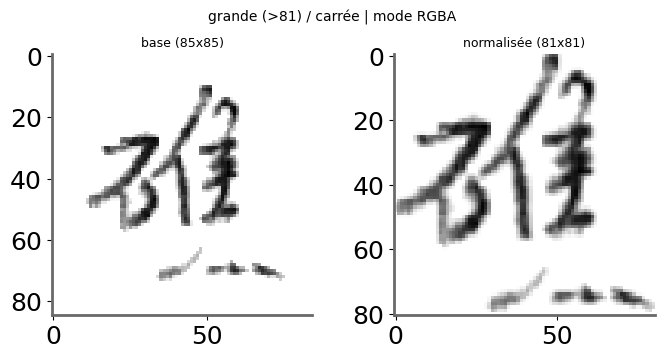

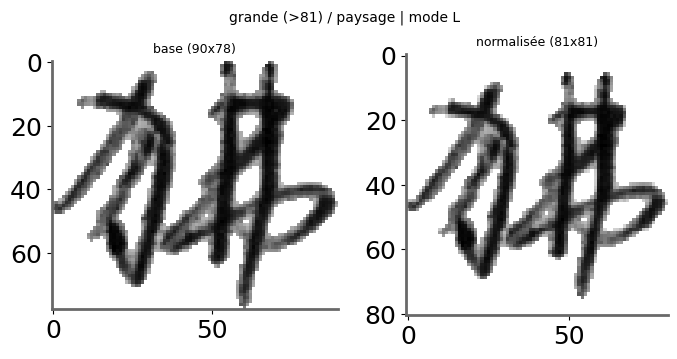

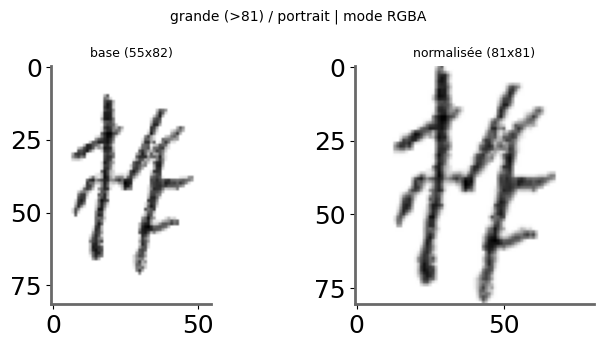

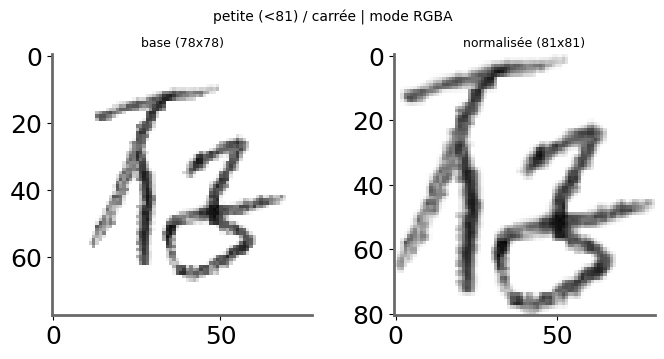

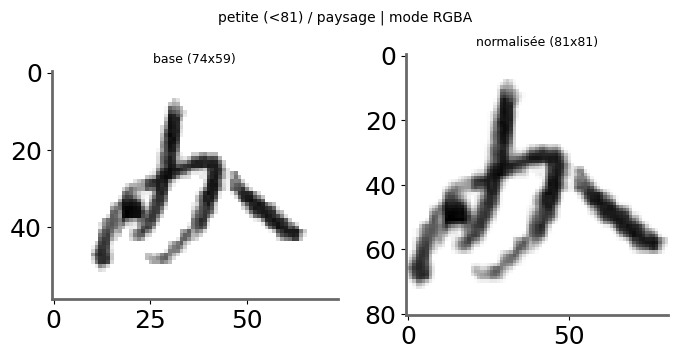

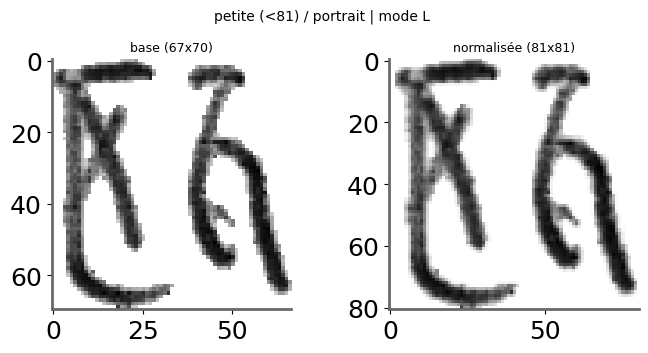

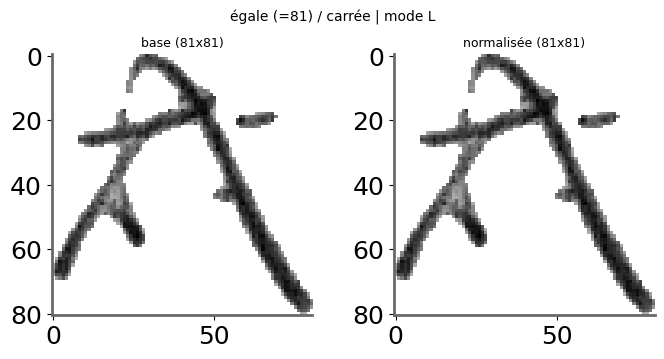

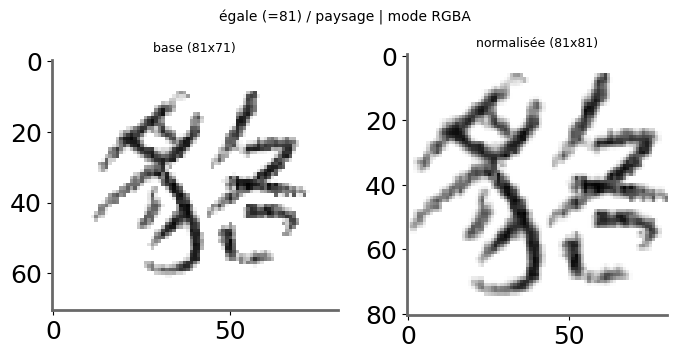

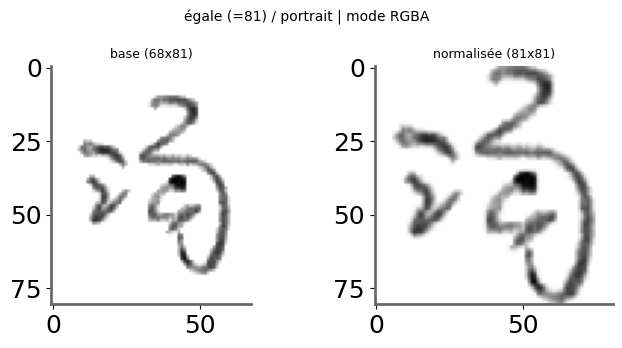

In [31]:
def show_case(title, path):
    base = np.asarray(Image.open(path).convert("L"))
    norm = normalise_images_pil(path)
    with Image.open(path) as im:
        mode = im.mode
    fig, axs = plt.subplots(1, 2, figsize=(7, 3.5))
    for ax, im_, t in zip(axs, (base, norm), ("base", "normalisée")):
        h, w = im_.shape
        ax.imshow(im_, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{t} ({w}x{h})", fontsize=9)
    fig.suptitle(f"{title} | mode {mode}", fontsize=10)
    plt.tight_layout()
    plt.show()

for (t, o), path in sorted(trouves.items()):
    show_case(f"{t} / {o}", path)

In [21]:
@dataclass
class Img:
    label: int
    pixels: np.ndarray | None          # (81, 81) uint8, None si l'image est illisible

def normalise_image_and_inverse_colors(sample): #on inverse les couleurs car on aplus de blanc que de noir
    path, label = sample
    arr = normalise_images_cv2(path)   
    if arr is None:
        return Img(label, None)
    return Img(label, 255 - arr)


In [ ]:
def save_dataset(dataset, name, size=81):
    n = len(dataset.samples)

    # Fichier .npy écrit directement sur disque (pas de saturation de la RAM)
    X = np.lib.format.open_memmap(f"{name}_x.npy", mode="w+",
                                  dtype=np.uint8, shape=(n, size, size))
    echecs = []

    for i, sample in enumerate(tqdm(dataset.samples, desc=name)):
        img = normalise_image_and_inverse_colors(sample)
        if img.pixels is None:
            echecs.append(i)   # on note l'image en échec (reste noire, X est initialisé à 0)
        else:
            X[i] = img.pixels

    X.flush()  # écrit les données sur le disque

    np.save(f"{name}_y.npy", np.array(dataset.targets, dtype=np.int64))  # labels
    np.save(f"{name}_failed.npy", np.array(echecs, dtype=np.int64))      # indices en échec

    print(f"{name} : {n} images | {len(echecs)} échecs")

save_dataset(train_dataset, "train_2")
save_dataset(test_dataset, "test_2")

In [32]:
y = np.load("test_2_y.npy")
print(y.shape, y.dtype, y.min(), y.max())
# print(y[:456])

x = np.load("test_2_x.npy", mmap_mode="r")
print(x.shape, x.dtype)
# print(x[:1,5])
assert len(x) == len(y)

failed = np.load("test_2_failed.npy")
print(len(failed), "échecs")

(776523,) int64 0 7329
(776523, 81, 81) uint8
0 échecs


In [7]:
# Reseau de neuronne

#Conv
# input shape : 81 * 81 donc modulo 9 modulo 3 donc on va faire du 3x3 

#Maxpooling : 
# Nout = floor((Nin -F +2P) / S) + 1

# N-3+1 * N-3+1 * 1
# padding 2 => N*N*1

class CNNHanzi_3x3(nn.Module):
    
    def __init__(self,num_class=10):
        super().__init__()
        self.num_class=num_class
        self.model = nn.Sequential(
            
            # first convolution  
            nn.Conv2d(in_channels=1, out_channels=64, kernel_size=3, stride=1, padding=1),            
            nn.ReLU(),
            # dim = (81 - 3 + 2)/1 + 1 = 81 => 81 x 81 x 64
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            # dim : pareil
            nn.MaxPool2d((3,3),stride=3,padding=0),  
            # dim = floor(81 - 3) / 3) + 1 = 27 * 27 * 64
            nn.Dropout2d(0.2),            # Combat overfitting
            
            # second convolution  
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            # dim = (27 - 3 + 2) / 1 + 1 = 27
            nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            # dim : pareil
            nn.MaxPool2d((3,3),stride=3,padding=0),  
            # dim = 27 - 3 / 3 => 8 + 1 = 9
            nn.Dropout2d(0.2),            # Combat overfitting

            # troisième convolution  
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            # dim = (9 - 3 + 2) / 1 + 1 = 9
            nn.Conv2d(in_channels=256, out_channels=256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            # dim : pareil
            nn.Dropout2d(0.2),   # Combat overfitting
            nn.AdaptiveAvgPool2d(3),             # ou nn.MaxPool2d(3) : 256×3×3
            nn.Flatten(),                 # convert feature map into feature vectors
            # MLP network   
            nn.Linear(256*3*3,1024),
            nn.ReLU(),
            nn.Dropout1d(0.2),            # Combat overfitting
            nn.Linear(1024, 7330),    # logits outpout
        )
        
    def forward(self, x):
        x=self.model(x)                   # forward pass
        return x

In [34]:
def conv_bn_relu(c_in, c_out):
    return [nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),  # padding=1 : garde la taille ; bias inutile avant BN
            nn.BatchNorm2d(c_out),                             # normalise : entraînement plus stable et rapide
            nn.ReLU(inplace=True)]                             # non-linéarité (inplace = moins de mémoire)

class CNNHanzi_3x3(nn.Module):
    def __init__(self, num_class=7330):
        super().__init__()
        self.num_class = num_class
        self.model = nn.Sequential(
            # --- Bloc 1 : détecte les traits simples (lignes, coins) ---
            *conv_bn_relu(1, 64),            # 1x81x81   -> 64x81x81
            *conv_bn_relu(64, 64),           # 64x81x81  (taille inchangée)
            nn.MaxPool2d(3),                 # 81 / 3 = 27 -> 64x27x27
            nn.Dropout2d(0.1),               # éteint des cartes entières (anti-overfitting léger)

            # --- Bloc 2 : combine les traits en formes (radicaux) ---
            *conv_bn_relu(64, 128),          # 64x27x27  -> 128x27x27
            *conv_bn_relu(128, 128),         # taille inchangée
            nn.MaxPool2d(3),                 # 27 / 3 = 9 -> 128x9x9
            nn.Dropout2d(0.1),

            # --- Bloc 3 : formes complexes (structure du caractère) ---
            *conv_bn_relu(128, 256),         # 128x9x9   -> 256x9x9
            *conv_bn_relu(256, 256),         # taille inchangée
            nn.MaxPool2d(3),                 # 9 / 3 = 3 -> 256x3x3
            nn.Flatten(),                    # 256*3*3 = 2304 valeurs (vecteur)

            # --- Classifieur (MLP) ---
            nn.Linear(256*3*3, 1024, bias=False),  # 2304 -> 1024
            nn.BatchNorm1d(1024),                  # normalise le vecteur
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),                       # dropout plus fort ici : c'est là qu'on overfit le plus
            nn.Linear(1024, num_class),            # 1024 -> 7330 logits (un par hanzi, pas de softmax)
        )

    def forward(self, x):
        return self.model(x)  # passe avant : image -> logits

In [5]:
#FIDLE
# def fit(model,X_train,Y_train,X_test,Y_test, EPOCHS = 5, BATCH_SIZE = 32):
    
#     loss = nn.CrossEntropyLoss()
#     optimizer = torch.optim.Adam(model.parameters(),lr=1e-3) #lr is the learning rate
#     model.train()
    
#     history=convergence_history_CrossEntropyLoss()
    
#     history.update(model,X_train,Y_train,X_test,Y_test)
    
#     n=X_train.shape[0] #number of observations in the training data
    
#     #stochastic gradient descent
#     for epoch in range(EPOCHS):
        
#         batch_start=0
#         epoch_shuffler=np.arange(n) 
#         np.random.shuffle(epoch_shuffler) #remark that 'utilsData.DataLoader' could be used instead
        
#         while batch_start+BATCH_SIZE < n:
#             #get mini-batch observation
#             mini_batch_observations = epoch_shuffler[batch_start:batch_start+BATCH_SIZE]
#             var_X_batch = Variable(X_train[mini_batch_observations,:,:]).float() #the input image is flattened
#             var_Y_batch = Variable(Y_train[mini_batch_observations])
            
#             #gradient descent step
#             optimizer.zero_grad()               #set the parameters gradients to 0
#             Y_pred_batch = model(var_X_batch)   #predict y with the current NN parameters
            
#             curr_loss = loss(Y_pred_batch, var_Y_batch)  #compute the current loss
#             curr_loss.backward()                         #compute the loss gradient w.r.t. all NN parameters
#             optimizer.step()                             #update the NN parameters
            
#             #prepare the next mini-batch of the epoch
#             batch_start+=BATCH_SIZE
            
#         history.update(model,X_train,Y_train,X_test,Y_test)
    
#     return history



In [9]:
from torch.utils.data import IterableDataset
import time
import numpy as np
import torch
import torch.nn as nn
import torch.multiprocessing as mp
from torch.utils.data import IterableDataset, DataLoader
import math
import time
from tqdm.auto import tqdm
class ChunkedHanziDataset(IterableDataset):
    def __init__(self, x_path, y_path, chunk_size=100_000, shuffle=True):
        self.x_path = x_path
        self.y_path = y_path
        self.chunk_size = chunk_size
        self.shuffle = shuffle
        
        # On lit juste la structure pour connaître la taille totale
        mmap_x = np.load(self.x_path, mmap_mode="r")
        self.total_samples = len(mmap_x)
        del mmap_x

    def __iter__(self):
        worker_info = torch.utils.data.get_worker_info()
        
        # 1. Gestion du multi-processing (num_workers > 0)
        if worker_info is None:
            start_idx, end_idx = 0, self.total_samples
        else:
            # Répartition équitable du dataset entre les workers
            per_worker = int(math.ceil(self.total_samples / float(worker_info.num_workers)))
            start_idx = worker_info.id * per_worker
            end_idx = min(start_idx + per_worker, self.total_samples)

        # Chaque worker ouvre son propre accès mmap
        x_mmap = np.load(self.x_path, mmap_mode='r')
        y_mmap = np.load(self.y_path, mmap_mode='r')

        # 2. Découpage de la portion du worker en chunks
        chunk_starts = list(range(start_idx, end_idx, self.chunk_size))
        
        if self.shuffle:
            np.random.shuffle(chunk_starts) # Mélange l'ordre d'appel des chunks

        for c_start in chunk_starts:
            c_end = min(c_start + self.chunk_size, end_idx)

            # 3. LECTURE SÉQUENTIELLE : On force la copie du mmap vers la RAM
            x_chunk = np.array(x_mmap[c_start:c_end])
            y_chunk = np.array(y_mmap[c_start:c_end])

            # 4. SHUFFLE EN RAM : Ne touche plus au disque
            if self.shuffle:
                indices = np.arange(len(x_chunk))
                np.random.shuffle(indices)
                x_chunk = x_chunk[indices]
                y_chunk = y_chunk[indices]

            # 5. Distribution des tensors
            for i in range(len(x_chunk)):
                img = torch.from_numpy(x_chunk[i]).unsqueeze(0) # (1, 81, 81) uint8
                label = torch.tensor(y_chunk[i], dtype=torch.long)
                yield img, label

# --- Entraînement ---
# chunk_size=100_000 images = ~656 Mo par worker. 
# Avec 4 workers, cela consommera ~2.6 Go de RAM, ce qui est parfait pour vos 16 Go.
train_ds = ChunkedHanziDataset("train_2_x.npy", "train_2_y.npy", chunk_size=100_000, shuffle=True)

train_loader = DataLoader(
    train_ds,
    batch_size=1024,
    pin_memory=True,
    drop_last=True,
    # Ne mettez PAS shuffle=True ou sampler ici
)

# --- Validation ---
# Pas besoin de shuffle pour la validation, lecture strictement séquentielle
test_ds = ChunkedHanziDataset("test_2_x.npy", "test_2_y.npy", chunk_size=100_000, shuffle=False)

val_loader = DataLoader(
    test_ds,
    batch_size=1024,
    pin_memory=True,
)

def evaluate(model, loader):
    model.eval()

    correct = 0
    total = 0
    loss_sum = 0.0

    lossf = nn.CrossEntropyLoss()

    pbar = tqdm(
        loader,
        desc="Validation",
        unit="batch",
        leave=False
    )

    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):

        for xb, yb in pbar:

            xb = (
                xb.cuda(non_blocking=True)
                .float()
                .div_(255)
                .contiguous(memory_format=torch.channels_last)
            )

            yb = yb.cuda(non_blocking=True)

            out = model(xb)

            loss = lossf(out, yb)

            loss_sum += loss.item() * yb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.size(0)

            pbar.set_postfix(
                loss=f"{loss.item():.4f}",
                acc=f"{correct / total:.4f}"
            )

    model.train()

    return loss_sum / total, correct / total


def fit(
    model,
    train_loader,
    val_loader,
    epochs=5,
    lr=1e-3,
    ckpt_path="hanzi_cnn_2.pt"
    ):

    torch.backends.cudnn.benchmark = True

    model = model.cuda().to(memory_format=torch.channels_last)

    opt = torch.optim.AdamW(
        model.parameters(),
        lr=lr
    )

    scaler = torch.amp.GradScaler()
    lossf = nn.CrossEntropyLoss()

    best_acc = 0.0

    for epoch in range(epochs):

        t0 = time.time()

        # Reset du compteur de pic VRAM
        torch.cuda.reset_peak_memory_stats()

        pbar = tqdm(
            train_loader,
            desc=f"Epoch {epoch + 1}/{epochs}",
            unit="batch"
        )

        for xb, yb in pbar:

            xb = (
                xb.cuda(non_blocking=True)
                .float()
                .div_(255)
                .contiguous(memory_format=torch.channels_last)
            )

            yb = yb.cuda(non_blocking=True)

            opt.zero_grad(set_to_none=True)

            with torch.autocast("cuda", dtype=torch.float16):
                loss = lossf(model(xb), yb)

            # Backward
            scaler.scale(loss).backward()

            # Optimizer
            scaler.step(opt)
            scaler.update()

            # VRAM actuelle
            vram = torch.cuda.memory_allocated() / 1024**3

            # Pic VRAM depuis le début de l'epoch
            peak_vram = torch.cuda.max_memory_allocated() / 1024**3

            pbar.set_postfix(
                loss=f"{loss.item():.4f}",
                vram=f"{vram:.2f}G",
                peak=f"{peak_vram:.2f}G"
            )

        # --- validation ---
        val_loss, val_acc = evaluate(
            model,
            val_loader
        )

        epoch_time = time.time() - t0

        peak_vram = (
            torch.cuda.max_memory_allocated()
            / 1024**3
        )

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"val_loss={val_loss:.4f} | "
            f"val_acc={val_acc:.4f} | "
            f"peak VRAM={peak_vram:.2f} GB | "
            f"temps={epoch_time:.0f}s"
        )

        # --- sauvegarde du meilleur modèle ---
        if val_acc > best_acc:

            best_acc = val_acc

            torch.save(
                {
                    "model": model.state_dict(),
                    "epoch": epoch,
                    "val_acc": val_acc
                },
                ckpt_path
            )

            print(
                f"  ✓ meilleur modèle sauvegardé "
                f"(acc={val_acc:.4f})"
            )

    return model


# --- modèle ---
model = CNNHanzi_3x3(7330)

model = fit(
    model,
    train_loader,
    val_loader,
    epochs=5,
    lr=1e-3
)

Epoch 1/5: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 1/5 | val_loss=10.3096 | val_acc=0.0314 | peak VRAM=6.66 GB | temps=2243s
  ✓ meilleur modèle sauvegardé (acc=0.0314)


Epoch 2/5: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 2/5 | val_loss=8.7193 | val_acc=0.0472 | peak VRAM=5.07 GB | temps=1702s
  ✓ meilleur modèle sauvegardé (acc=0.0472)


Epoch 3/5: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 3/5 | val_loss=4.0475 | val_acc=0.2147 | peak VRAM=5.07 GB | temps=1720s
  ✓ meilleur modèle sauvegardé (acc=0.2147)


Epoch 4/5: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 4/5 | val_loss=3.1448 | val_acc=0.3907 | peak VRAM=5.07 GB | temps=1724s
  ✓ meilleur modèle sauvegardé (acc=0.3907)


Epoch 5/5: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 5/5 | val_loss=2.7224 | val_acc=0.4726 | peak VRAM=5.07 GB | temps=1722s
  ✓ meilleur modèle sauvegardé (acc=0.4726)


In [14]:
# --- modèle ---
model = CNNHanzi_3x3(7330)

# --- charger le meilleur checkpoint précédent ---
checkpoint = torch.load(
    "hanzi_cnn_3.pt",
    map_location="cuda"
)

model.load_state_dict(checkpoint["model"])


<All keys matched successfully>

In [15]:
print(
    f"Checkpoint chargé : "
    f"epoch={checkpoint['epoch'] + 1}, "
    f"val_acc={checkpoint['val_acc']:.4f}"
)

model = fit(
    model,
    train_loader,
    val_loader,
    epochs=25,
    lr=1e-4,
    ckpt_path="hanzi_cnn_4.pt",
)


Checkpoint chargé : epoch=1, val_acc=0.7386


Epoch 1/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 1/25 | val_loss=1.0307 | val_acc=0.7613 | peak VRAM=5.07 GB | temps=1670s
  ✓ meilleur modèle sauvegardé (acc=0.7613)


Epoch 2/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 2/25 | val_loss=1.0342 | val_acc=0.7626 | peak VRAM=5.07 GB | temps=1668s
  ✓ meilleur modèle sauvegardé (acc=0.7626)


Epoch 3/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 3/25 | val_loss=0.9826 | val_acc=0.7740 | peak VRAM=5.07 GB | temps=1669s
  ✓ meilleur modèle sauvegardé (acc=0.7740)


Epoch 4/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 4/25 | val_loss=0.9889 | val_acc=0.7756 | peak VRAM=5.07 GB | temps=1660s
  ✓ meilleur modèle sauvegardé (acc=0.7756)


Epoch 5/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 5/25 | val_loss=1.3884 | val_acc=0.7292 | peak VRAM=5.07 GB | temps=1642s


Epoch 6/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 6/25 | val_loss=1.2197 | val_acc=0.7282 | peak VRAM=5.07 GB | temps=1660s


Epoch 7/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 7/25 | val_loss=0.9998 | val_acc=0.7772 | peak VRAM=5.07 GB | temps=1666s
  ✓ meilleur modèle sauvegardé (acc=0.7772)


Epoch 8/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:01, ?batch/s]

Epoch 8/25 | val_loss=0.9934 | val_acc=0.7712 | peak VRAM=5.07 GB | temps=1651s


Epoch 9/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 9/25 | val_loss=1.0524 | val_acc=0.7663 | peak VRAM=5.07 GB | temps=1656s


Epoch 10/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 10/25 | val_loss=1.0408 | val_acc=0.7714 | peak VRAM=5.07 GB | temps=1655s


Epoch 11/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 11/25 | val_loss=1.3511 | val_acc=0.7364 | peak VRAM=5.07 GB | temps=1650s


Epoch 12/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 12/25 | val_loss=1.2753 | val_acc=0.7560 | peak VRAM=5.07 GB | temps=1651s


Epoch 13/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 13/25 | val_loss=0.9827 | val_acc=0.7785 | peak VRAM=5.07 GB | temps=1656s
  ✓ meilleur modèle sauvegardé (acc=0.7785)


Epoch 14/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 14/25 | val_loss=1.3297 | val_acc=0.7332 | peak VRAM=5.07 GB | temps=1651s


Epoch 15/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 15/25 | val_loss=1.1360 | val_acc=0.7647 | peak VRAM=5.07 GB | temps=1666s


Epoch 16/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 16/25 | val_loss=1.2499 | val_acc=0.7496 | peak VRAM=5.07 GB | temps=1662s


Epoch 17/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 17/25 | val_loss=1.0331 | val_acc=0.7757 | peak VRAM=5.07 GB | temps=1651s


Epoch 18/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 18/25 | val_loss=1.3189 | val_acc=0.7438 | peak VRAM=5.07 GB | temps=1661s


Epoch 19/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 19/25 | val_loss=1.1504 | val_acc=0.7659 | peak VRAM=5.07 GB | temps=1648s


Epoch 20/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 20/25 | val_loss=1.1973 | val_acc=0.7548 | peak VRAM=5.07 GB | temps=1655s


Epoch 21/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 21/25 | val_loss=1.5505 | val_acc=0.7074 | peak VRAM=5.07 GB | temps=1658s


Epoch 22/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 22/25 | val_loss=1.3525 | val_acc=0.7377 | peak VRAM=5.07 GB | temps=1645s


Epoch 23/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 23/25 | val_loss=1.1606 | val_acc=0.7682 | peak VRAM=5.07 GB | temps=1682s


Epoch 24/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 24/25 | val_loss=1.4756 | val_acc=0.7173 | peak VRAM=5.07 GB | temps=1726s


Epoch 25/25: 0batch [00:00, ?batch/s]

Validation: 0batch [00:00, ?batch/s]

Epoch 25/25 | val_loss=1.6577 | val_acc=0.7012 | peak VRAM=5.07 GB | temps=1750s


In [ ]:
#FIDLE
# batch_size  = 512
# epochs      = 128

# history=fit(model,x_train,y_train,x_test,y_test,EPOCHS=epochs,BATCH_SIZE = batch_size)

In [26]:
# Load test datas

y = np.load("test_2_y.npy")
print(y.shape, y.dtype, y.min(), y.max())
x = np.load("test_2_x.npy", mmap_mode="r")
print(x.shape, x.dtype)

print( len(x) == len(y) )

(776523,) int64 0 7329
(776523, 81, 81) uint8
True


In [35]:
# Load models


checkpoint = torch.load(
    "hanzi_cnn_4.pt",
    map_location="cpu",
    weights_only=True
)

# Récupérer les poids
state_dict = checkpoint["model"]

# Afficher les informations
print("Epoch:", checkpoint["epoch"])
print("Val accuracy:", checkpoint["val_acc"])

model = CNNHanzi_3x3()

model.load_state_dict(state_dict)
model.eval()


Epoch: 12
Val accuracy: 0.7784882096216081


CNNHanzi_3x3(
  (model): Sequential(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=3, stride=3, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.1, inplace=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (12): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)

In [37]:
var_x_test = torch.tensor(x[:,:,:]).float()
var_y_test = torch.tensor(y[:])
y_pred = model(var_x_test)

loss = nn.CrossEntropyLoss()
curr_loss = loss(y_pred, var_y_test)

val_loss = curr_loss.item()
val_accuracy  = float( (torch.argmax(y_pred, dim= 1) == var_y_test).float().mean() )

print('Test loss     :', val_loss)
print('Test accuracy :', val_accuracy)

RuntimeError: [enforce fail at alloc_cpu.cpp:127] err == 0. DefaultCPUAllocator: can't allocate memory: you tried to allocate 20379069612 bytes. Error code 12 (Cannot allocate memory)

In [42]:
device = "cuda" if torch.cuda.is_available() else "cpu"

# Données + vérifications
x = np.load("test_2_x.npy", mmap_mode="r")
y = np.load("test_2_y.npy")
assert len(x) == len(y), (len(x), len(y))
print(x.shape, x.dtype, x[:1000].min(), x[:1000].max())  # vérifier l'échelle des valeurs

# Modèle
ckpt = torch.load("hanzi_cnn_4.pt", map_location="cpu", weights_only=True)
model = CNNHanzi_3x3()
model.load_state_dict(ckpt["model"])
model.to(device).eval()

n_classes = model(torch.zeros(1, 1, *x.shape[1:], device=device)).shape[1]
assert 0 <= y.min() and y.max() < n_classes, (y.min(), y.max(), n_classes)

# Évaluation
loss_fn = nn.CrossEntropyLoss(reduction="sum")
loss_sum = torch.zeros((), device=device)
top1 = torch.zeros((), device=device)
top5 = torch.zeros((), device=device)

with torch.inference_mode():
    for i in range(0, len(x), 512):
        xb = torch.from_numpy(np.array(x[i:i+512], dtype=np.float32)).unsqueeze(1)
        # + même normalisation qu'à l'entraînement ici
        yb = torch.from_numpy(y[i:i+512].astype(np.int64))
        xb, yb = xb.to(device, non_blocking=True), yb.to(device)

        logits = model(xb)
        loss_sum += loss_fn(logits, yb)
        idx = logits.topk(5, dim=1).indices
        top1 += (idx[:, 0] == yb).sum()
        top5 += (idx == yb[:, None]).any(dim=1).sum()

n = len(y)
print(f"loss {loss_sum.item()/n:.4f} | top-1 {top1.item()/n:.4f} | top-5 {top5.item()/n:.4f}")

(776523, 81, 81) uint8 0 255


KeyboardInterrupt: 

In [46]:
PREPROC = lambda t: t / 255.0

loss_fn = nn.CrossEntropyLoss(reduction="sum")
loss_sum = torch.zeros((), device=device)
top1 = torch.zeros((), device=device)
top5 = torch.zeros((), device=device)
batch_size = 1024

with torch.inference_mode():
    for i in range(0, len(x), batch_size):
        xb = torch.from_numpy(np.array(x[i:i + batch_size], dtype=np.float32))
        xb = PREPROC(xb.pin_memory().to(device, non_blocking=True).unsqueeze(1))
        yb = y_gpu[i:i + batch_size]

        logits = model(xb)   # float32, sans autocast
        loss_sum += loss_fn(logits, yb)
        top5_idx = logits.topk(5, dim=1).indices
        top1 += (top5_idx[:, 0] == yb).sum()
        top5 += (top5_idx == yb[:, None]).any(dim=1).sum()

n = len(y)
print(f"Test loss : {loss_sum.item() / n:.4f}")
print(f"Top-1 acc : {top1.item() / n:.4f}")
print(f"Top-5 acc : {top5.item() / n:.4f}")



Test loss : 0.9827
Top-1 acc : 0.7785
Top-5 acc : 0.9458


Test loss : 0.9827
Top-1 acc : 0.7785
Top-5 acc : 0.9458


/usr/local/lib/python3.11/site-packages/fidle/scrawler.py:242: RuntimeWarning: invalid value encountered in divide
  cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]


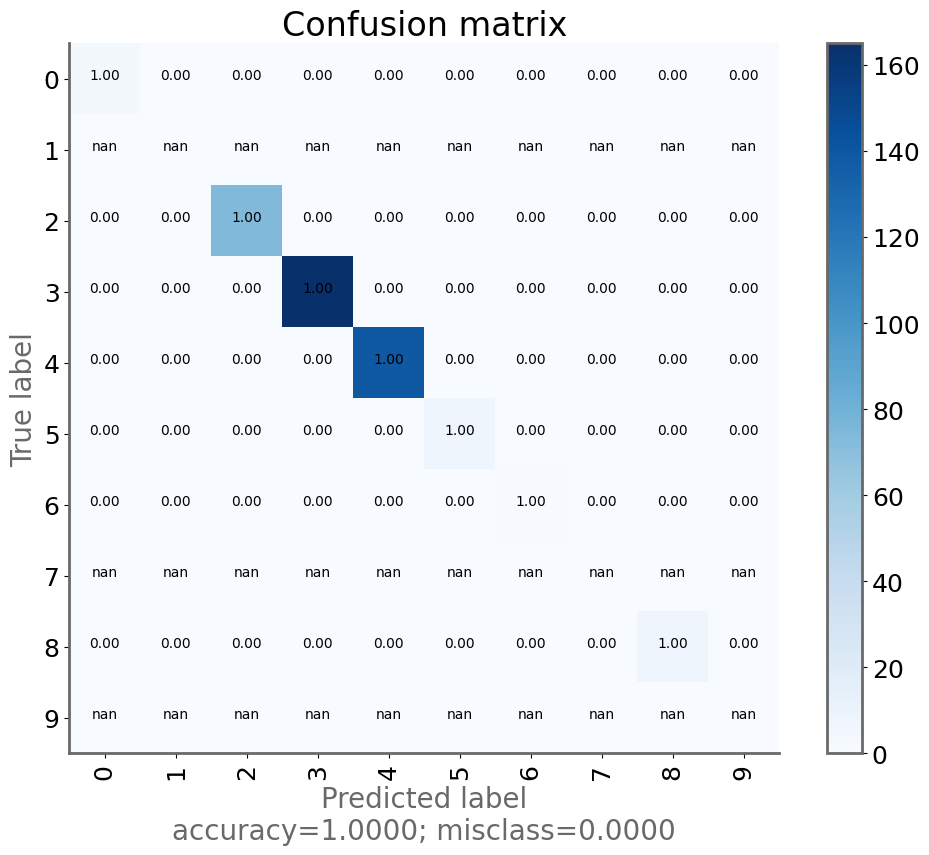

In [51]:
all_preds = []
all_labels = []

PREPROC = lambda t: t / 255.0

loss_fn = nn.CrossEntropyLoss(reduction="sum")
loss_sum = torch.zeros((), device=device)
top1 = torch.zeros((), device=device)
top5 = torch.zeros((), device=device)
batch_size = 1024

with torch.inference_mode():
    for i in range(0, len(x), batch_size):
        xb = torch.from_numpy(np.array(x[i:i + batch_size], dtype=np.float32))
        xb = PREPROC(xb.pin_memory().to(device, non_blocking=True).unsqueeze(1))
        yb = y_gpu[i:i + batch_size]

        logits = model(xb)

        loss_sum += loss_fn(logits, yb)

        top5_idx = logits.topk(5, dim=1).indices
        top1 += (top5_idx[:, 0] == yb).sum()
        top5 += (top5_idx == yb[:, None]).any(dim=1).sum()

        ypred = logits.argmax(dim=1)

        all_preds.extend(ypred.cpu().numpy())
        all_labels.extend(yb.cpu().numpy())

n = len(x)

print(f"Test loss : {loss_sum.item() / n:.4f}")
print(f"Top-1 acc : {top1.item() / n:.4f}")
print(f"Top-5 acc : {top5.item() / n:.4f}")

fidle.scrawler.confusion_matrix(
    np.array(all_labels),
    np.array(all_preds),
    range(10)
)


In [1]:
classes = qnp.unique(all_labels)

fidle.scrawler.confusion_matrix(
    all_labels.numpy(),
    all_preds.numpy(),
    classes[:20]
)


NameError: name 'np' is not defined

In [47]:
fidle.scrawler.confusion_matrix(top1,logits, range(10))

TypeError: Input should have at least 1 dimension i.e. satisfy `len(x.shape) > 0`, got scalar `tensor(604533., device='cuda:0')` instead.

In [ ]:
fidle.scrawler.history(history, figsize=(6,4))

In [ ]:
y_pred = model(var_x_test)
np_y_pred_label = torch.argmax(y_pred, dim= 1).numpy().astype(np.uint8)

np_x_test=x_test.numpy().astype(np.float64)
np_y_test=y_test.numpy().astype(np.uint8)

fidle.scrawler.images(np_x_test, np_y_test, range(0,60), columns=12, x_size=1, y_size=1, y_pred=np_y_pred_label)

In [ ]:
errors=[ i for i in range(len(np_y_test)) if np_y_pred_label[i]!=np_y_test[i] ]
errors=errors[:min(24,len(errors))]
fidle.scrawler.images(np_x_test, np_y_test, errors[:15], columns=6, x_size=2, y_size=2, y_pred=np_y_pred_label)

In [ ]:
fidle.scrawler.confusion_matrix(np_y_test,np_y_pred_label, range(10))

<div class="todo">
    A few things you can do for fun:
    <ul>
        <li>Changing the network architecture (layers, number of neurons, etc.)</li>
        <li>Display a summary of the network</li>
        <li>Retrieve and display the softmax output of the network, to evaluate its "doubts".</li>
    </ul>
</div>